In [65]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

from mpl_toolkits.mplot3d import Axes3D
from sklearn.linear_model import LogisticRegression

In [66]:
df=pd.read_csv(r"input\breast_cancer_mod.csv")
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,0,0,0,0,0,0,0,0,0,1,...,0,0,0,1,1,0,0,1,1,0
1,0,1,0,1,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0
2,0,1,0,0,0,0,0,0,0,1,...,1,0,1,0,1,1,0,1,1,0
3,0,1,0,0,0,0,0,0,0,1,...,1,0,0,0,0,0,0,1,1,0
4,0,0,0,1,0,0,0,0,0,0,...,0,0,1,0,0,0,0,1,1,0


In [67]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   mean radius              569 non-null    int64
 1   mean texture             569 non-null    int64
 2   mean perimeter           569 non-null    int64
 3   mean area                569 non-null    int64
 4   mean smoothness          569 non-null    int64
 5   mean compactness         569 non-null    int64
 6   mean concavity           569 non-null    int64
 7   mean concave points      569 non-null    int64
 8   mean symmetry            569 non-null    int64
 9   mean fractal dimension   569 non-null    int64
 10  radius error             569 non-null    int64
 11  texture error            569 non-null    int64
 12  perimeter error          569 non-null    int64
 13  area error               569 non-null    int64
 14  smoothness error         569 non-null    int64
 15  compac

In [68]:
df.isna().sum().sum()

np.int64(0)

In [69]:
df['target'].value_counts()

target
1    357
0    212
Name: count, dtype: int64

<Axes: xlabel='target', ylabel='count'>

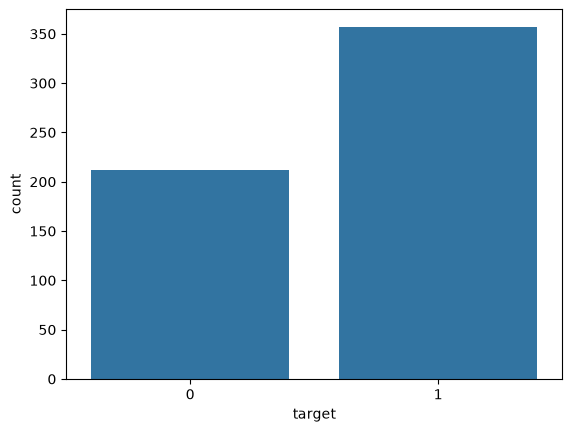

In [70]:
sns.barplot(df['target'].value_counts())


In [71]:
feature=df.drop('target',axis=1)
labels=df['target']
X_train, X_test, y_train, y_test= train_test_split(feature,labels,test_size=0.25,random_state=24,stratify=labels)

In [72]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((426, 30), (143, 30), (426,), (143,))

In [76]:
X_train['total']=X_train.astype(np.int16).sum(axis=1)
X_train['target']=y_train
X_train.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,total,target
146,0,1,0,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,26,0
389,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,30,1
424,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,30,1
116,0,1,0,1,1,1,1,1,1,1,...,1,1,1,1,1,0,1,1,25,0
313,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,29,1


In [77]:
accuracy={}
for b in range(X_train.shape[1]):
    X_train['y_pred']=X_train['total']>=b
    accuracy[b]=accuracy_score(y_true=X_train['target'],y_pred=X_train['y_pred'])

In [78]:
best_b=max(accuracy,key=accuracy.get)
best_b

27